## 1. Import libraries

In [106]:


import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt



from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, confusion_matrix,
    classification_report, roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score
)
from sklearn.inspection import permutation_importance

import joblib

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

In [107]:
# Keep Telco_Customer_Churn.csv in the same folder as this notebook.
data = pd.read_csv('Telco_Customer_Churn.csv')

print("Dataset shape:", data.shape)
display(data.head())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.850,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.950,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.300,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.65,Yes


In [108]:
# Summary of numerical columns
display(data.describe())

,SeniorCitizen,tenure,MonthlyCharges
count,"7,043.000","7,043.000","7,043.000"
mean,0.162,32.371,64.762
std,0.369,24.559,30.090
min,0.000,0.000,18.250
25%,0.000,9.000,35.500
50%,0.000,29.000,70.350
75%,0.000,55.000,89.850
max,1.000,72.000,118.750


In [109]:
# Missing values and missing percentage
missing_summary = pd.DataFrame({
    'Missing_Count': data.isnull().sum(),
    'Missing_Percentage': (data.isnull().mean() * 100).round(2)
})
display(missing_summary.sort_values('Missing_Count', ascending=False))

,Missing_Count,Missing_Percentage
customerID,0,0.000
gender,0,0.000
SeniorCitizen,0,0.000
Partner,0,0.000
Dependents,0,0.000
tenure,0,0.000
PhoneService,0,0.000
MultipleLines,0,0.000
InternetService,0,0.000
OnlineSecurity,0,0.000


In [110]:


# Unique values in categorical columns
for col in data.select_dtypes(include='object').columns:
    print(f'\\n{col}: {data[col].nunique()} unique values')
    print(data[col].value_counts(dropna=False).head(10))

\ncustomerID: 7043 unique values
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
9305-CDSKC    1
1452-KIOVK    1
6713-OKOMC    1
7892-POOKP    1
6388-TABGU    1
Name: count, dtype: int64
\ngender: 2 unique values
gender
Male      3555
Female    3488
Name: count, dtype: int64
\nPartner: 2 unique values
Partner
No     3641
Yes    3402
Name: count, dtype: int64
\nDependents: 2 unique values
Dependents
No     4933
Yes    2110
Name: count, dtype: int64
\nPhoneService: 2 unique values
PhoneService
Yes    6361
No      682
Name: count, dtype: int64
\nMultipleLines: 3 unique values
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64
\nInternetService: 3 unique values
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
\nOnlineSecurity: 3 unique values
OnlineSecurity
No                     3498
Yes                    2019
No internet service 

C:\Users\sahil dhatunde\AppData\Local\Temp\ipykernel_33092\1375382722.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in data.select_dtypes(include='object').columns:


In [111]:

# Convert TotalCharges to numeric.
# Blank strings or invalid values are converted to NaN.
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')

print("Missing TotalCharges after conversion:", data['TotalCharges'].isna().sum())

# Inspect rows before deciding how to handle them
display(data[data['TotalCharges'].isna()].head(10))

Missing TotalCharges after conversion: 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.550,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.250,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.850,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.750,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.050,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.850,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.350,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.000,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.700,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.350,NaN,No


In [112]:
# Remove rows where TotalCharges is missing.
# In this dataset, these are commonly new customers with tenure = 0.
rows_before = len(data)
data = data.dropna(subset=['TotalCharges'])

print("Rows removed:", rows_before - len(data))
print("Shape after cleaning:", data.shape)

# Remove exact duplicates if present
duplicates = data.duplicated().sum()
if duplicates > 0:
    data = data.drop_duplicates().copy()

print("Duplicate rows remaining:", data.duplicated().sum())

Rows removed: 11
Shape after cleaning: (7032, 21)
Duplicate rows remaining: 0


In [113]:
service_columns = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df["NumAddOnServices"] = (
    df[service_columns] == "Yes"
).sum(axis=1)

df[["NumAddOnServices", "Churn"]].head()

,NumAddOnServices,Churn
0,1,No
1,2,No
2,2,Yes
3,3,No
4,0,Yes


In [114]:
df["HasInternetService"] = np.where(
    df["InternetService"] == "No",
    0,
    1
)

df[["InternetService", "HasInternetService"]].head()

,InternetService,HasInternetService
0,DSL,1
1,DSL,1
2,DSL,1
3,DSL,1
4,Fiber optic,1


In [115]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "New",
        "Medium",
        "Long",
        "Very Long"
    ]
)

df[["tenure", "TenureGroup"]].head()

,tenure,TenureGroup
0,1,New
1,34,Long
2,2,New
3,45,Long
4,2,New


In [116]:
df["MonthlyChargeCategory"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 35, 70, 100, 120],
    labels=[
        "Low",
        "Medium",
        "High",
        "Very High"
    ]
)

df[["MonthlyCharges", "MonthlyChargeCategory"]].head()

,MonthlyCharges,MonthlyChargeCategory
0,29.850,Low
1,56.950,Medium
2,53.850,Medium
3,42.300,Medium
4,70.700,High


In [117]:
df["HasFamily"] = np.where(
    (df["Partner"] == "Yes") |
    (df["Dependents"] == "Yes"),
    1,
    0
)

df[["Partner", "Dependents", "HasFamily"]].head()

,Partner,Dependents,HasFamily
0,Yes,No,1
1,No,No,0
2,No,No,0
3,No,No,0
4,No,No,0


In [118]:
target = 'Churn'

numeric_features = [
    'tenure', 'MonthlyCharges', 'TotalCharges',
    'NumAddOnServices', 'HasInternetService', 'HasFamily'
]

categorical_features = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents',
    'PhoneService', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaperlessBilling', 'PaymentMethod',
    'TenureGroup', 'MonthlyChargeCategory'
]

In [119]:
# Number and percentage of customers in each target class
print(data[target].value_counts())


Churn
No     5163
Yes    1869
Name: count, dtype: int64


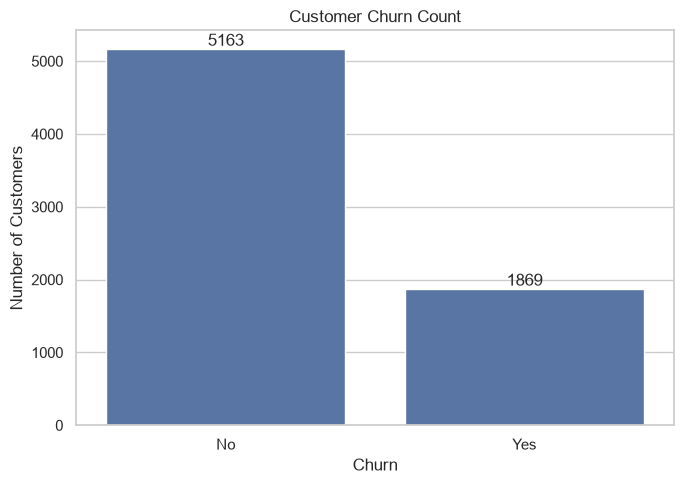

In [120]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=data, x=target)
plt.title('Customer Churn Count')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

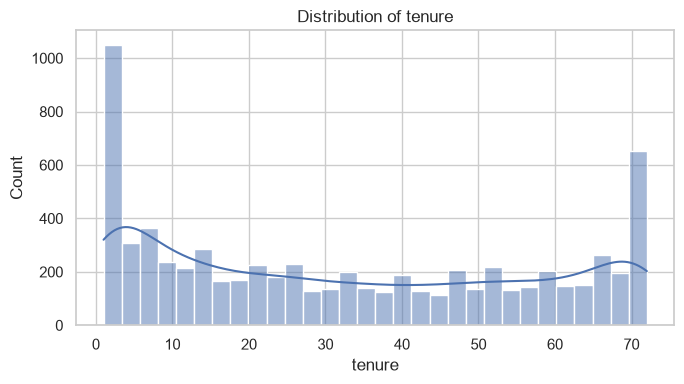

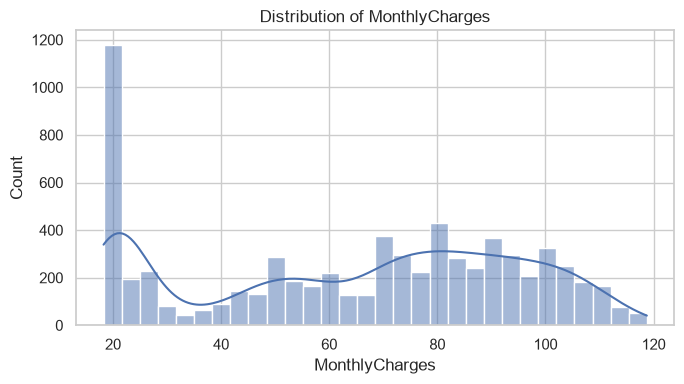

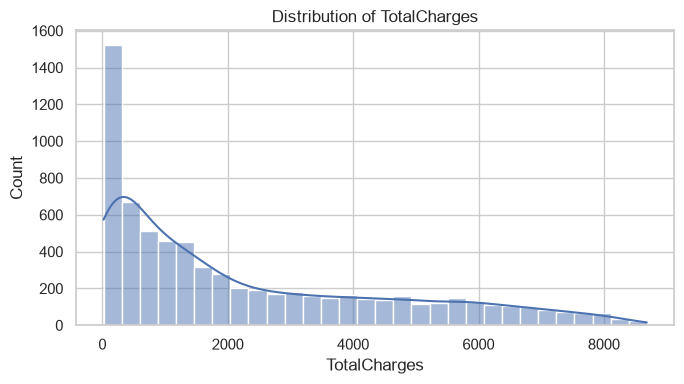

ValueError: Could not interpret value `NumAddOnServices` for `x`. An entry with this name does not appear in `data`.

<Figure size 700x400 with 0 Axes>

In [121]:
for col in numeric_features:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=data, x=col, kde=True, bins=30)
    plt.title('Distribution of ' + col)
    plt.tight_layout()
    plt.show()

### 9.2 Compare numerical variables by churn

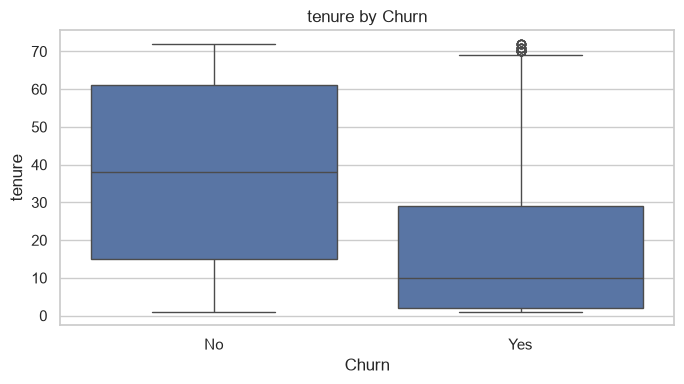

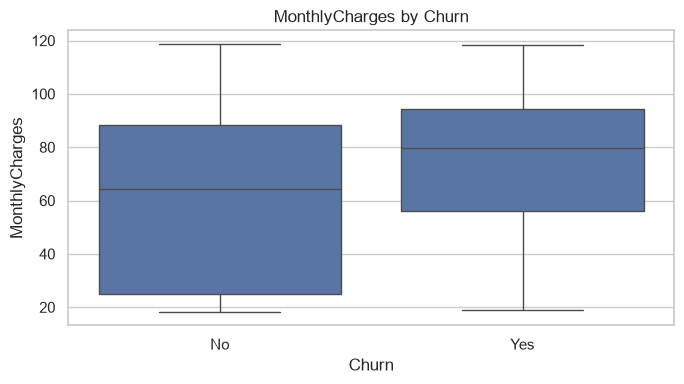

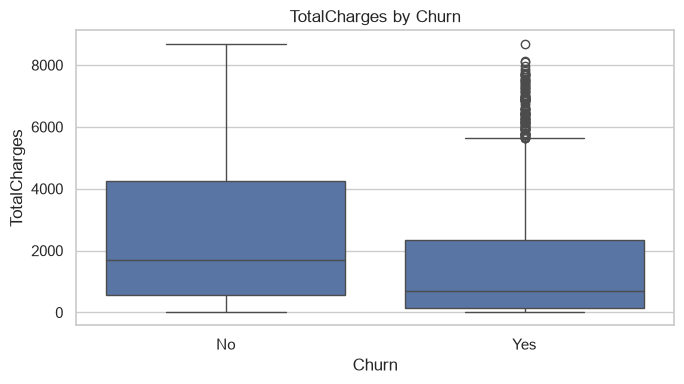

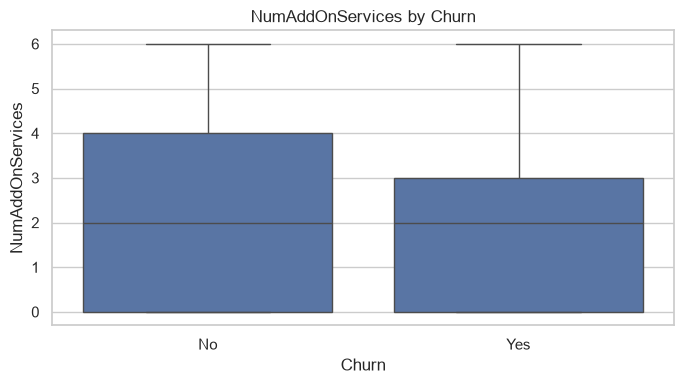

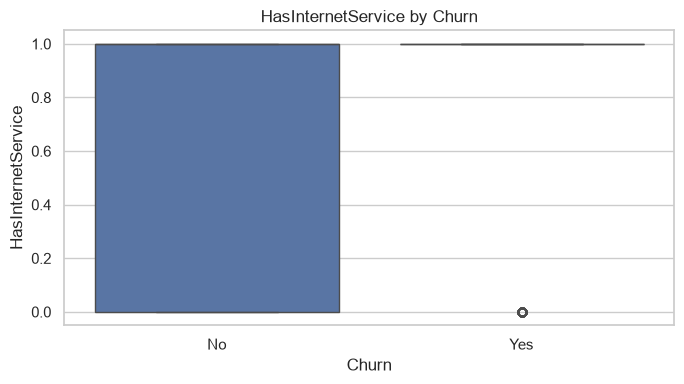

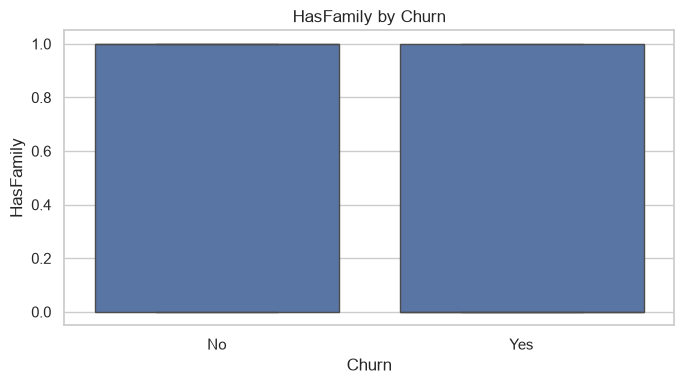

In [ ]:
for col in numeric_features:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=data, x='Churn', y=col)
    plt.title(col + ' by Churn')
    plt.tight_layout()
    plt.show()

In [ ]:
# Group-wise descriptive statistics
for col in numeric_features:
    print('\\n', col)
    display(data.groupby('Churn')[col].agg(
        ['count', 'mean', 'median', 'std', 'min', 'max']
    ))

\n tenure


,count,mean,median,std,min,max
Churn,,,,,,
No,5163,37.650,38.000,24.077,1,72
Yes,1869,17.979,10.000,19.531,1,72


\n MonthlyCharges


,count,mean,median,std,min,max
Churn,,,,,,
No,5163,61.307,64.450,31.095,18.250,118.750
Yes,1869,74.441,79.650,24.666,18.850,118.350


\n TotalCharges


,count,mean,median,std,min,max
Churn,,,,,,
No,5163,"2,555.344","1,683.600","2,329.457",18.800,"8,672.450"
Yes,1869,"1,531.796",703.550,"1,890.823",18.850,"8,684.800"


... (2 outputs left out)

\n HasInternetService


,count,mean,median,std,min,max
Churn,,,,,,
No,5163,0.727,1.000,0.445,0,1
Yes,1869,0.940,1.000,0.238,0,1


\n HasFamily


,count,mean,median,std,min,max
Churn,,,,,,
No,5163,0.582,1.000,0.493,0,1
Yes,1869,0.399,0.000,0.490,0,1


**Interpretation:** Compare the medians and spreads for churned and retained customers. For example, a lower median tenure among churned customers would suggest an association between shorter tenure and churn. It does not prove that tenure alone causes churn.

In [ ]:
outlier_results = []

for col in numeric_features:
    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (data[col] < lower) | (data[col] > upper)

    outlier_results.append({
        'Feature': col,
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'Lower_Bound': lower,
        'Upper_Bound': upper,
        'Outlier_Count': int(mask.sum()),
        'Outlier_Percentage': mask.mean() * 100
    })

outlier_table = pd.DataFrame(outlier_results)
display(outlier_table)

,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,tenure,9.000,55.000,46.000,-60.000,124.000,0,0.000
1,MonthlyCharges,35.587,89.862,54.275,-45.825,171.275,0,0.000
2,TotalCharges,401.450,"3,794.738","3,393.288","-4,688.481","8,884.669",0,0.000
3,NumAddOnServices,0.000,3.000,3.000,-4.500,7.500,0,0.000
4,HasInternetService,1.000,1.000,0.000,1.000,1.000,1520,21.615
5,HasFamily,0.000,1.000,1.000,-1.500,2.500,0,0.000


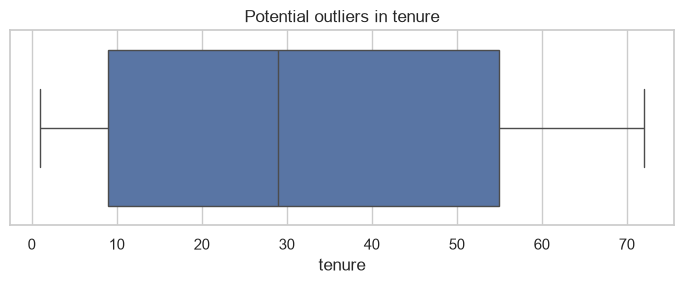

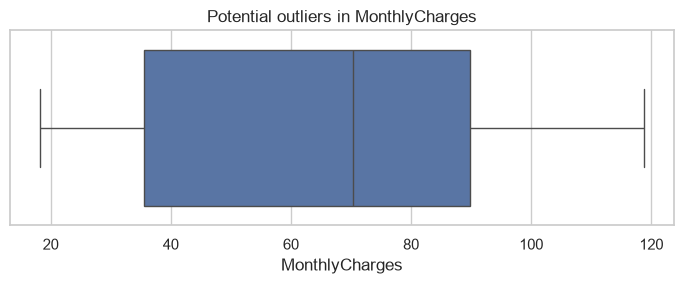

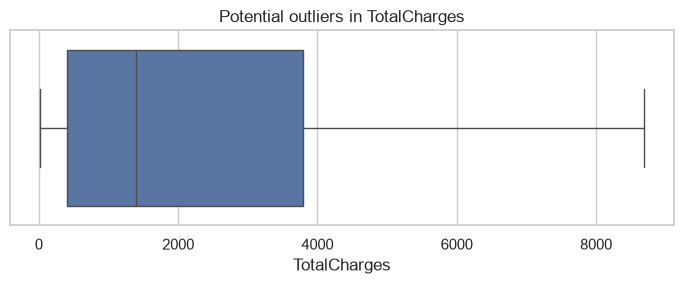

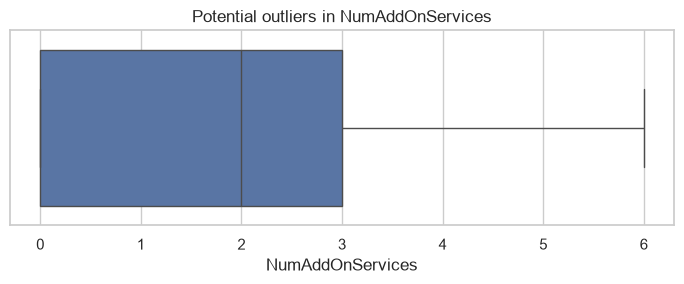

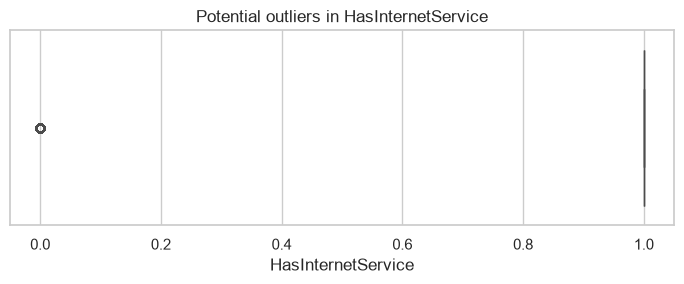

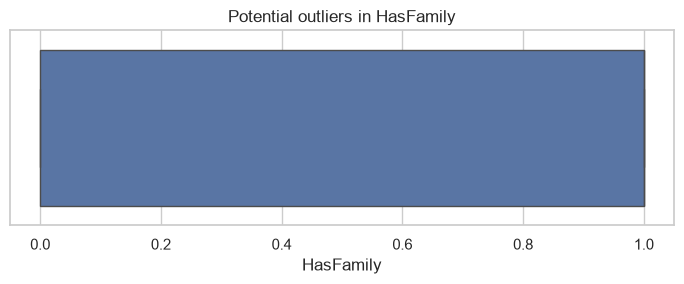

In [ ]:
# Boxplots for visual outlier inspection
for col in numeric_features:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=data[col])
    plt.title('Potential outliers in ' + col)
    plt.tight_layout()
    plt.show()

In [ ]:
# Inspect some flagged records without deleting them
for col in numeric_features:
    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    flagged_rows = data[(data[col] < lower) | (data[col] > upper)]
    print(f'\\n{col}: {len(flagged_rows)} flagged observations')
    display(flagged_rows[['customerID', col, 'Churn']].head(10))

\ntenure: 0 flagged observations


,customerID,tenure,Churn


\nMonthlyCharges: 0 flagged observations


,customerID,MonthlyCharges,Churn


\nTotalCharges: 0 flagged observations


,customerID,TotalCharges,Churn


... (2 outputs left out)

\nHasInternetService: 1520 flagged observations


,customerID,HasInternetService,Churn
11,7469-LKBCI,0,No
16,8191-XWSZG,0,No
21,1680-VDCWW,0,No
22,1066-JKSGK,0,Yes
33,7310-EGVHZ,0,No
42,9867-JCZSP,0,No
58,3957-SQXML,0,No
68,3170-NMYVV,0,No
71,0731-EBJQB,0,No
73,8028-PNXHQ,0,No


\nHasFamily: 0 flagged observations


,customerID,HasFamily,Churn


## 12. Categorical EDA — churn rates

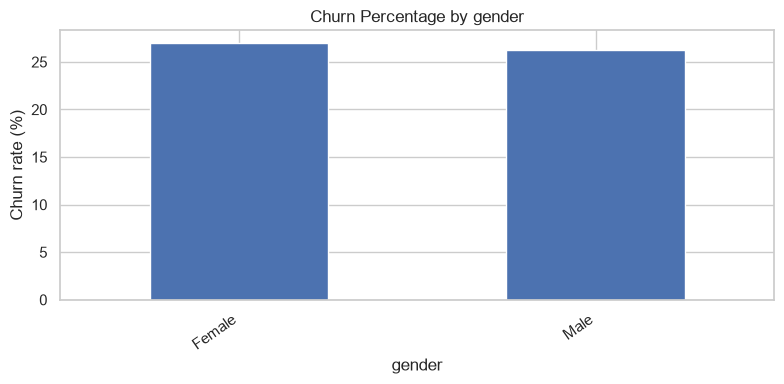

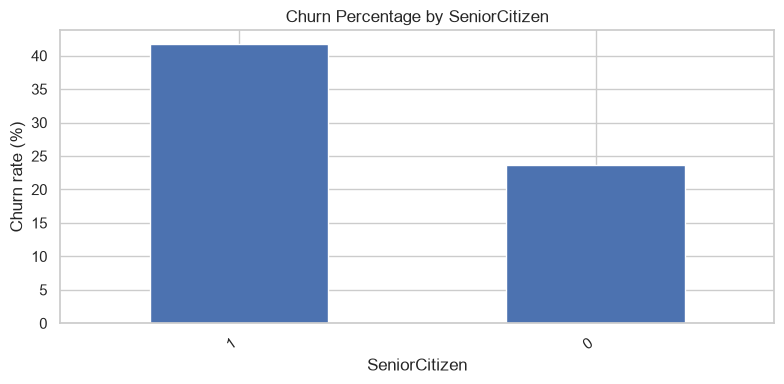

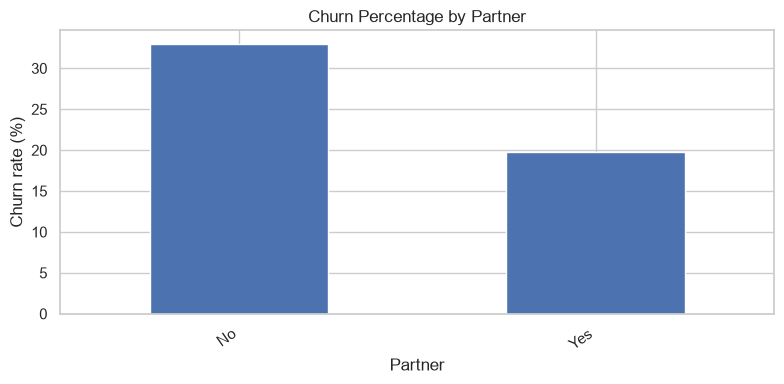

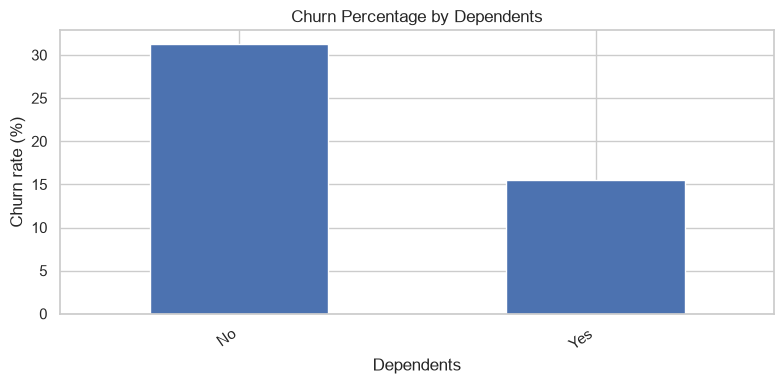

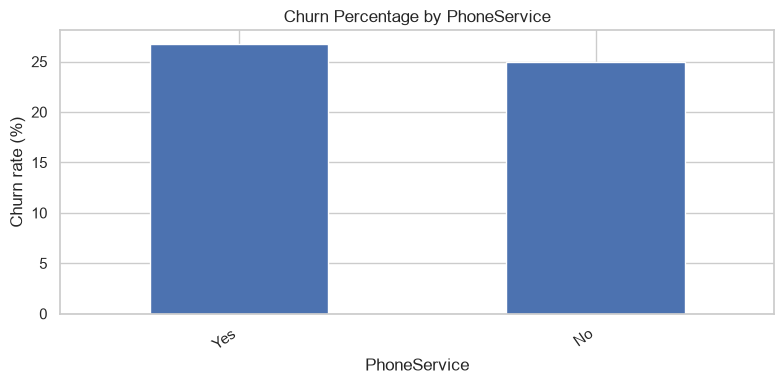

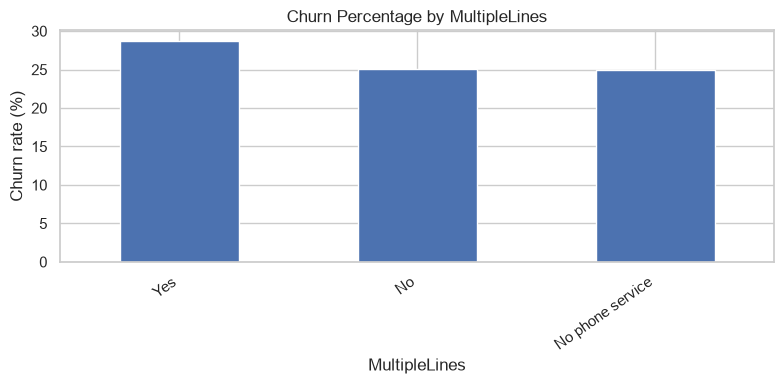

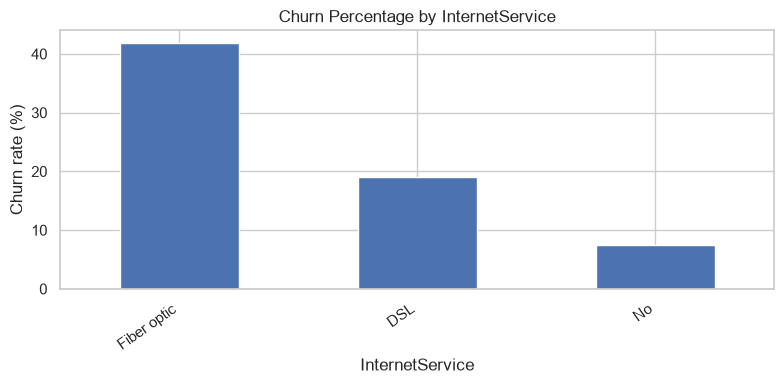

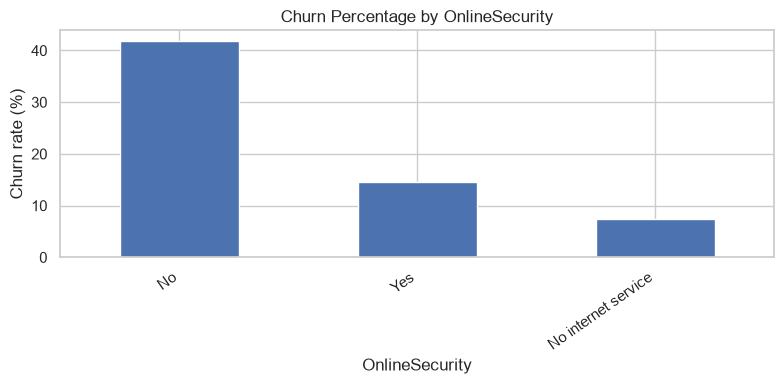

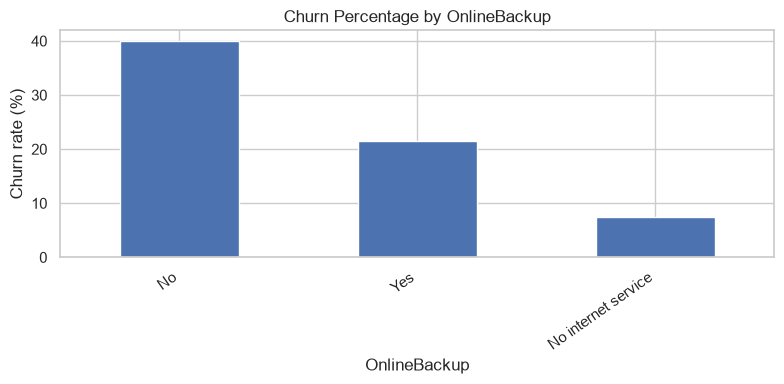

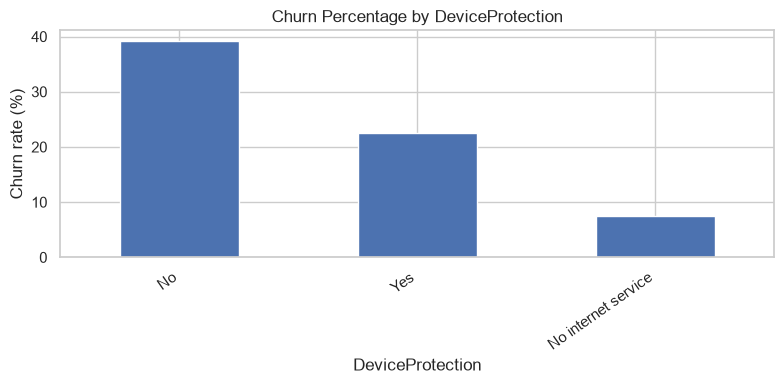

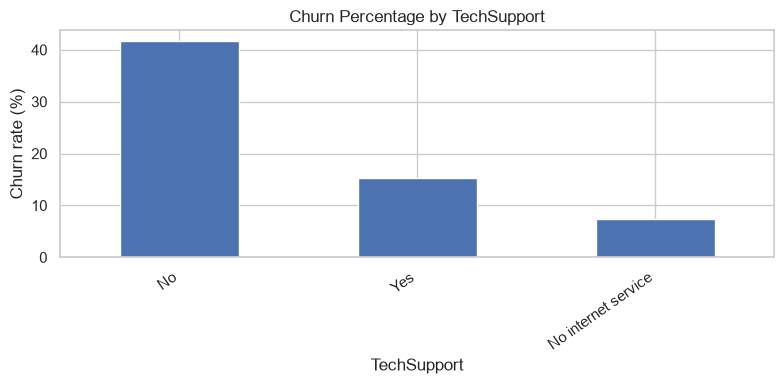

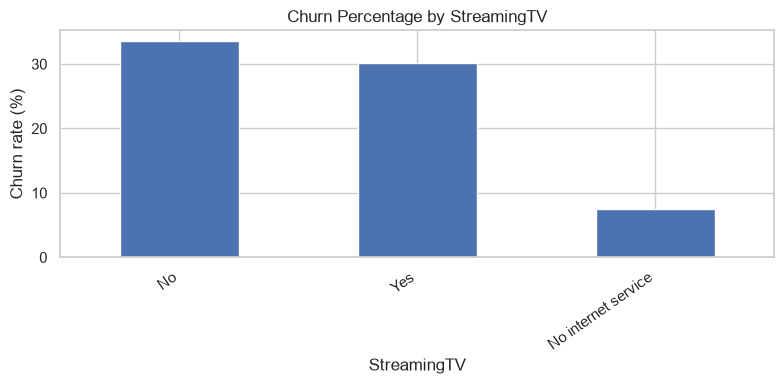

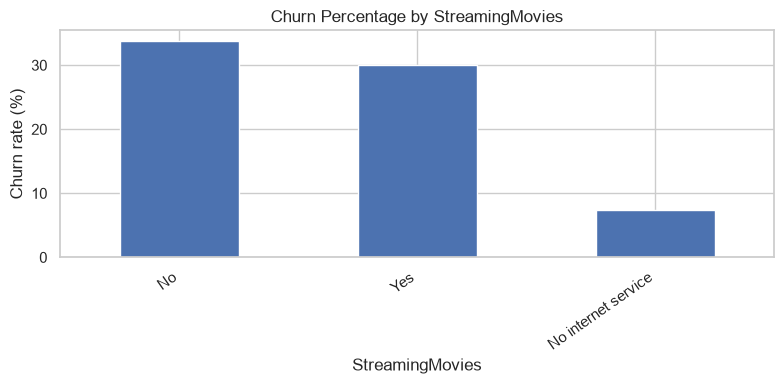

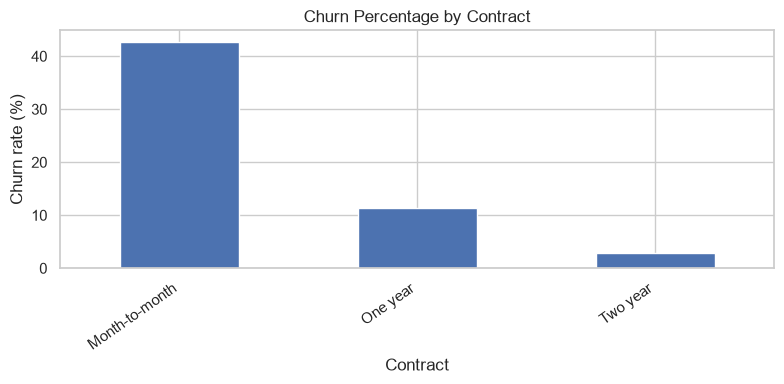

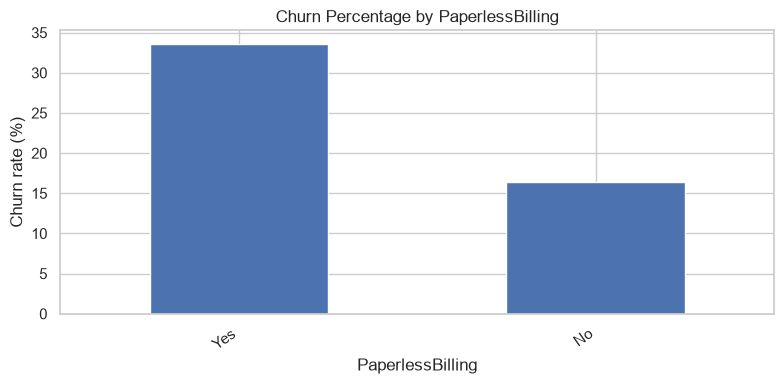

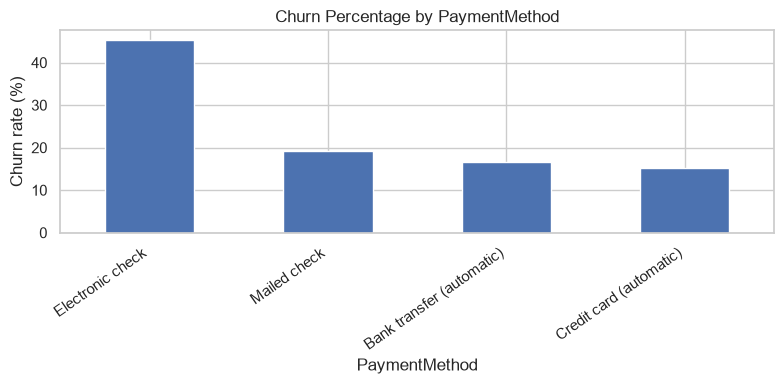

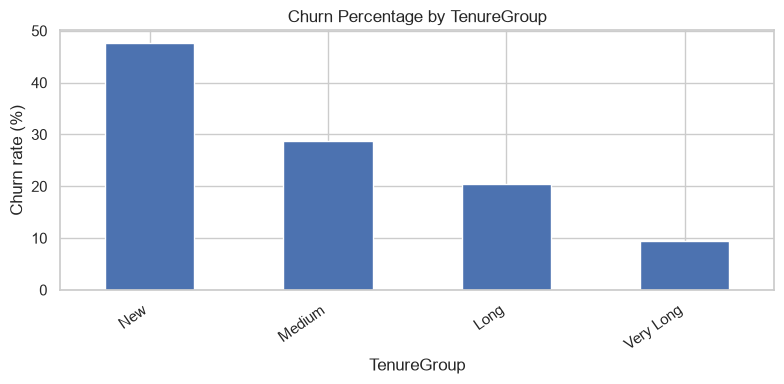

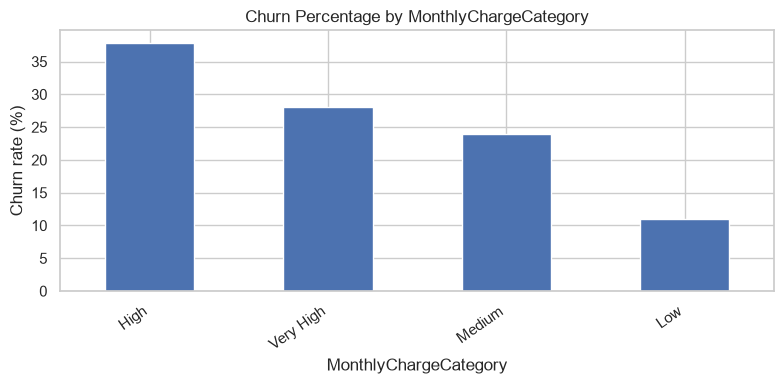

In [ ]:
for col in categorical_features:
    churn_table = pd.crosstab(data[col], data['Churn'], normalize='index') * 100

    if 'Yes' in churn_table.columns:
        churn_table['Yes'].sort_values(ascending=False).plot(
            kind='bar', figsize=(8, 4)
        )
        plt.title('Churn Percentage by ' + col)
        plt.xlabel(col)
        plt.ylabel('Churn rate (%)')
        plt.xticks(rotation=35, ha='right')
        plt.tight_layout()
        plt.show()

Correlation analysis

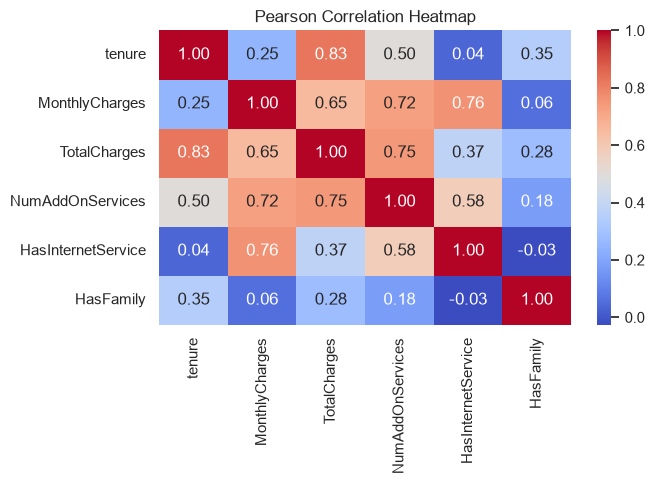

,tenure,MonthlyCharges,TotalCharges,NumAddOnServices,HasInternetService,HasFamily
tenure,1.000,0.247,0.826,0.495,0.038,0.347
MonthlyCharges,0.247,1.000,0.651,0.725,0.763,0.056
TotalCharges,0.826,0.651,1.000,0.746,0.375,0.277
NumAddOnServices,0.495,0.725,0.746,1.000,0.579,0.176
HasInternetService,0.038,0.763,0.375,0.579,1.000,-0.026
HasFamily,0.347,0.056,0.277,0.176,-0.026,1.000


In [ ]:
# Pearson correlation among numeric variables
correlation = data[numeric_features].corr(method='pearson')

plt.figure(figsize=(7, 5))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Pearson Correlation Heatmap')
plt.tight_layout()
plt.show()

display(correlation)

15. Prepare features and target

In [ ]:
X = data[numeric_features + categorical_features].copy()
y = data['Churn'].map({'No': 0, 'Yes': 1})

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

Preprocessing pipeline

In [ ]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

Baseline model

In [ ]:
logistic_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

logistic_pipeline.fit(X_train, y_train)

y_pred_lr = logistic_pipeline.predict(X_test)
y_proba_lr = logistic_pipeline.predict_proba(X_test)[:, 1]

In [ ]:
def evaluate_model(model_name, y_true, y_pred, y_probability):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    results = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'ROC_AUC': roc_auc_score(y_true, y_probability),
    }

    print(f'===== {model_name} =====')
    for metric, value in results.items():
        if metric != 'Model':
            print(f'{metric}: {value:.4f}')

    print("\\nConfusion matrix:")
    print(cm)

    print("\\nClassification report:")
    print(classification_report(y_true, y_pred, zero_division=0))

    return results

In [ ]:
lr_results = evaluate_model(
    'Logistic Regression', y_test, y_pred_lr, y_proba_lr
)

===== Logistic Regression =====
Accuracy: 0.7365
Precision: 0.5028
Recall: 0.7914
F1: 0.6150
ROC_AUC: 0.8368
\nConfusion matrix:
[[1110  439]
 [ 117  444]]
\nClassification report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1549
           1       0.50      0.79      0.61       561

    accuracy                           0.74      2110
   macro avg       0.70      0.75      0.71      2110
weighted avg       0.80      0.74      0.75      2110



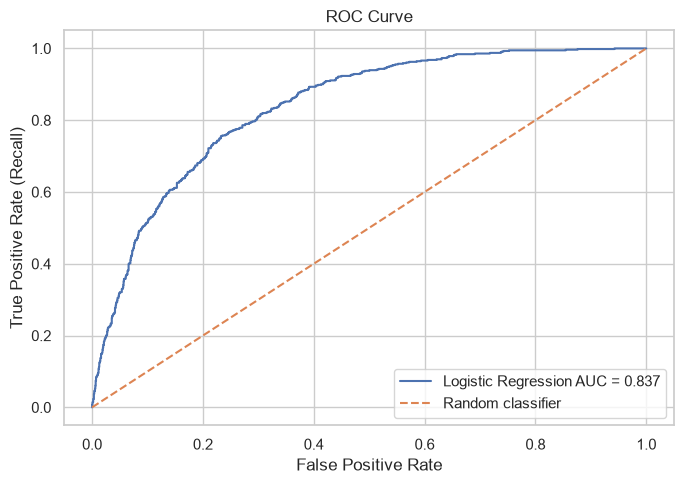

In [ ]:
fpr, tpr, roc_thresholds = roc_curve(y_test, y_proba_lr)
roc_auc_value = roc_auc_score(y_test, y_proba_lr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'Logistic Regression AUC = {roc_auc_value:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve')
plt.legend()
plt.tight_layout()
plt.show()

## 22. Cross-validation

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'average_precision': 'average_precision'
}

cv_results = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
)

cv_summary = pd.DataFrame({
    metric: [
        cv_results[f'test_{metric}'].mean(),
        cv_results[f'test_{metric}'].std()
    ]
    for metric in scoring
}, index=['Mean', 'Standard_Deviation']).T

display(cv_summary)

,Mean,Standard_Deviation
accuracy,0.753,0.008
precision,0.523,0.010
recall,0.800,0.015
f1,0.633,0.011
roc_auc,0.849,0.012
average_precision,0.670,0.038


Random Forest model

In [ ]:
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        random_state=RANDOM_STATE,
    ))
])

rf_pipeline.fit(X_train, y_train)

y_pred_rf = rf_pipeline.predict(X_test)
y_proba_rf = rf_pipeline.predict_proba(X_test)[:, 1]

rf_results = evaluate_model(
    'Random Forest', y_test, y_pred_rf, y_proba_rf
)

===== Random Forest =====
Accuracy: 0.7597
Precision: 0.5427
Recall: 0.6114
F1: 0.5750
ROC_AUC: 0.8100
\nConfusion matrix:
[[1260  289]
 [ 218  343]]
\nClassification report:
              precision    recall  f1-score   support

           0       0.85      0.81      0.83      1549
           1       0.54      0.61      0.58       561

    accuracy                           0.76      2110
   macro avg       0.70      0.71      0.70      2110
weighted avg       0.77      0.76      0.76      2110



In [ ]:
comparison = pd.DataFrame([lr_results, rf_results])
display(comparison.sort_values('ROC_AUC', ascending=False))

,Model,Accuracy,Precision,Recall,Specificity,F1,Balanced_Accuracy,ROC_AUC,PR_AUC
0,Logistic Regression,0.736,0.503,0.791,0.717,0.615,0.754,0.837,0.625
1,Random Forest,0.760,0.543,0.611,0.813,0.575,0.712,0.810,0.584


In [ ]:
# Save preprocessing and model together
joblib.dump(logistic_pipeline, 'telecom_churn_logistic_pipeline.pkl')
print("Model pipeline saved.")

Model pipeline saved.


In [ ]:

loaded_model = joblib.load('telecom_churn_logistic_pipeline.pkl')